In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score
from statsmodels.tsa.arima.model import ARIMA
import joblib
import os
import warnings
warnings.filterwarnings("ignore")

os.makedirs("models", exist_ok=True)
print("Libraries loaded!")

Libraries loaded!


In [ ]:
#load dataset


orders = pd.read_csv("data/orders.csv")
order_products = pd.read_csv("data/order_products__train.csv")
products = pd.read_csv("data/products.csv")
aisles = pd.read_csv("data/aisles.csv")
departments = pd.read_csv("data/departments.csv")

print(f"Orders: {len(orders):,}")
print(f"Order Products: {len(order_products):,}")
print(f"Products: {len(products):,}")
print(f"Aisles: {len(aisles):,}")
print(f"Departments: {len(departments):,}")

display(orders.head())

Orders: 3,421,083
Order Products: 1,384,617
Products: 49,688
Aisles: 134
Departments: 21


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0
3,2254736,1,prior,4,4,7,29.0
4,431534,1,prior,5,4,15,28.0


In [3]:
#explore the data
# Merge all data together
print("Merging datasets...")

order_products_full = order_products.merge(products, on="product_id")
order_products_full = order_products_full.merge(aisles, on="aisle_id")
order_products_full = order_products_full.merge(departments, on="department_id")
order_products_full = order_products_full.merge(orders[["order_id", "user_id", "order_dow", "order_hour_of_day", "days_since_prior_order"]], on="order_id")

print(f"Merged shape: {order_products_full.shape}")
display(order_products_full.head())

Merging datasets...
Merged shape: (1384617, 13)


,order_id,product_id,add_to_cart_order,reordered,product_name,aisle_id,department_id,aisle,department,user_id,order_dow,order_hour_of_day,days_since_prior_order
0,1,49302,1,1,Bulgarian Yogurt,120,16,yogurt,dairy eggs,112108,4,10,9.0
1,1,11109,2,1,Organic 4% Milk Fat Whole Milk Cottage Cheese,108,16,other creams cheeses,dairy eggs,112108,4,10,9.0
2,1,10246,3,0,Organic Celery Hearts,83,4,fresh vegetables,produce,112108,4,10,9.0
3,1,49683,4,0,Cucumber Kirby,83,4,fresh vegetables,produce,112108,4,10,9.0
4,1,43633,5,1,Lightly Smoked Sardines in Olive Oil,95,15,canned meat seafood,canned goods,112108,4,10,9.0


In [4]:
#create monthly sales data
print("Creating monthly aggregations...")

# Simulate monthly data from order counts
# Each order_number represents a time period
orders_sorted = orders.sort_values(["user_id", "order_number"])

# Group by order_number as proxy for time (month)
monthly = orders.groupby("order_number").agg(
    total_orders=("order_id", "count"),
    unique_users=("user_id", "nunique")
).reset_index()

# Simulate revenue (avg basket = Rs. 2500)
monthly["revenue"] = monthly["total_orders"] * 2500
monthly["daily_revenue"] = monthly["revenue"] / 30
monthly["month_num"] = monthly["order_number"]

# Keep first 24 months
monthly = monthly[monthly["order_number"] <= 24].copy()

print(f"Monthly data shape: {monthly.shape}")
display(monthly.head(10))

Creating monthly aggregations...
Monthly data shape: (24, 6)


,order_number,total_orders,unique_users,revenue,daily_revenue,month_num
0,1,206209,206209,515522500,1.718408e+07,1
1,2,206209,206209,515522500,1.718408e+07,2
2,3,206209,206209,515522500,1.718408e+07,3
3,4,206209,206209,515522500,1.718408e+07,4
4,5,182223,182223,455557500,1.518525e+07,5
5,6,162633,162633,406582500,1.355275e+07,6
6,7,146468,146468,366170000,1.220567e+07,7
7,8,132618,132618,331545000,1.105150e+07,8
8,9,120918,120918,302295000,1.007650e+07,9
9,10,110728,110728,276820000,9.227333e+06,10


Training Model 1: Monthly Revenue Prediction...
MAE: Rs. 27,477,010
R² Score: 0.9400
Predicted Revenue Next Month: Rs. 30,088,858


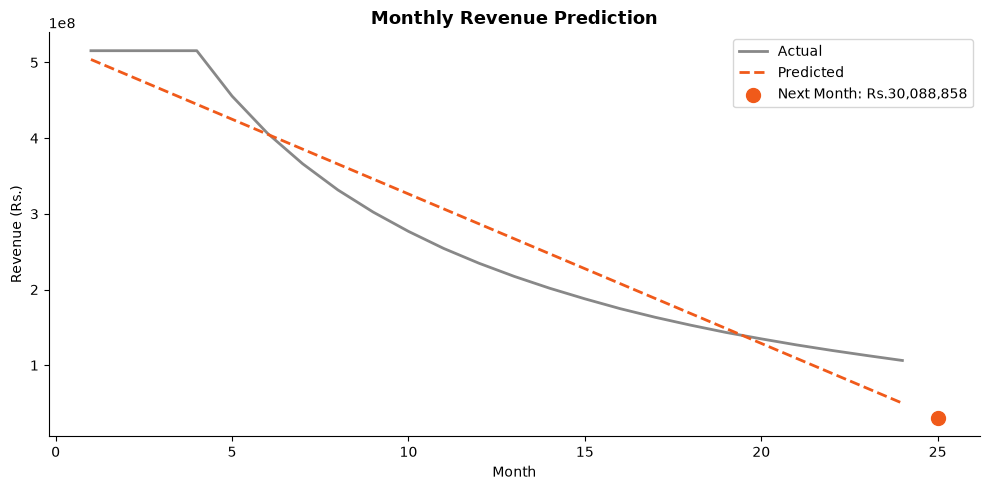

Saved: models/model_revenue.pkl


In [5]:
#monthly revenue prediction
print("Training Model 1: Monthly Revenue Prediction...")

X = monthly[["month_num"]].values
y = monthly["revenue"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model_revenue = LinearRegression()
model_revenue.fit(X_train, y_train)

y_pred = model_revenue.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

next_month = np.array([[25]])
predicted_revenue = model_revenue.predict(next_month)[0]

print(f"MAE: Rs. {mae:,.0f}")
print(f"R² Score: {r2:.4f}")
print(f"Predicted Revenue Next Month: Rs. {predicted_revenue:,.0f}")

# Plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly["month_num"], monthly["revenue"], color="#888888", label="Actual", linewidth=2)
ax.plot(monthly["month_num"], model_revenue.predict(X), color="#f05a1a", label="Predicted", linewidth=2, linestyle="--")
ax.scatter([25], [predicted_revenue], color="#f05a1a", s=100, zorder=5, label=f"Next Month: Rs.{predicted_revenue:,.0f}")
ax.set_title("Monthly Revenue Prediction", fontsize=13, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (Rs.)")
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig("models/chart_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

joblib.dump(model_revenue, "models/model_revenue.pkl")
print("Saved: models/model_revenue.pkl")

In [6]:
#daily revenue prediction
print("Training Model 2: Daily Revenue Prediction...")

X = monthly[["month_num"]].values
y = monthly["daily_revenue"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model_daily = LinearRegression()
model_daily.fit(X_train, y_train)

y_pred = model_daily.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

predicted_daily = model_daily.predict([[25]])[0]

print(f"MAE: Rs. {mae:,.0f}")
print(f"R² Score: {r2:.4f}")
print(f"Predicted Daily Revenue: Rs. {predicted_daily:,.0f}")

joblib.dump(model_daily, "models/model_daily_revenue.pkl")
print("Saved: models/model_daily_revenue.pkl")

Training Model 2: Daily Revenue Prediction...
MAE: Rs. 915,900
R² Score: 0.9400
Predicted Daily Revenue: Rs. 1,002,962
Saved: models/model_daily_revenue.pkl


Training Model 3: User Growth Prediction...
MAE: 10991 users
R² Score: 0.9400
Predicted Users Next Month: 12,036


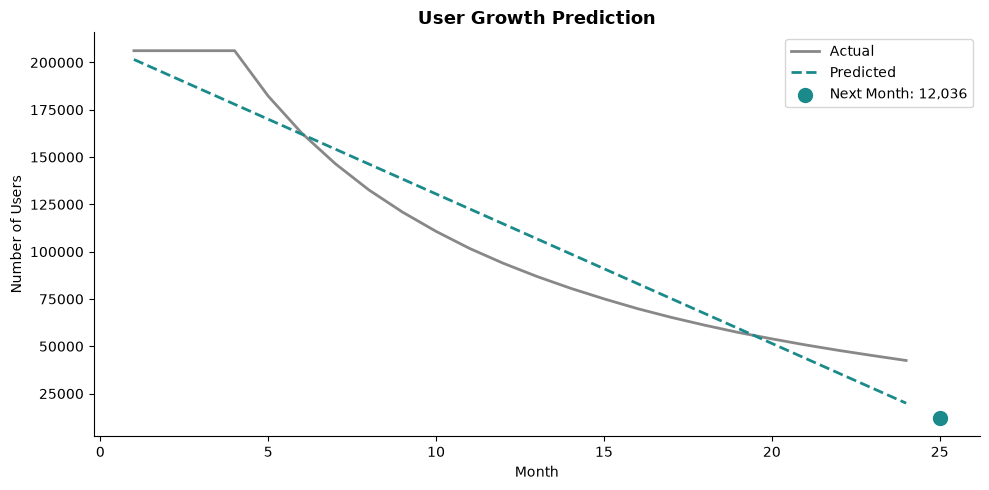

Saved: models/model_users.pkl


In [7]:
#user growth prediction
print("Training Model 3: User Growth Prediction...")

X = monthly[["month_num"]].values
y = monthly["unique_users"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model_users = LinearRegression()
model_users.fit(X_train, y_train)

y_pred = model_users.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

predicted_users = model_users.predict([[25]])[0]

print(f"MAE: {mae:.0f} users")
print(f"R² Score: {r2:.4f}")
print(f"Predicted Users Next Month: {predicted_users:,.0f}")

# Plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly["month_num"], monthly["unique_users"], color="#888888", label="Actual", linewidth=2)
ax.plot(monthly["month_num"], model_users.predict(X), color="#1a8a8a", label="Predicted", linewidth=2, linestyle="--")
ax.scatter([25], [predicted_users], color="#1a8a8a", s=100, zorder=5, label=f"Next Month: {predicted_users:,.0f}")
ax.set_title("User Growth Prediction", fontsize=13, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Users")
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig("models/chart_users.png", dpi=150, bbox_inches="tight")
plt.show()

joblib.dump(model_users, "models/model_users.pkl")
print("Saved: models/model_users.pkl")

In [8]:
#Top category prediction
print("Training Model 4: Top Category Prediction...")

# Get department sales per order_number
dept_monthly = order_products_full.merge(
    orders[["order_id", "order_number"]], on="order_id"
)
dept_monthly = dept_monthly[dept_monthly["order_number"] <= 24]

dept_counts = dept_monthly.groupby(["order_number", "department"])["product_id"].count().reset_index()
dept_counts.columns = ["order_number", "department", "sales"]

# Find top department per month
top_dept = dept_counts.loc[dept_counts.groupby("order_number")["sales"].idxmax()].reset_index(drop=True)
top_dept = top_dept.merge(monthly[["month_num", "revenue", "unique_users"]], left_on="order_number", right_on="month_num")

le = LabelEncoder()
top_dept["dept_encoded"] = le.fit_transform(top_dept["department"])

X = top_dept[["order_number", "revenue", "unique_users"]].values
y = top_dept["dept_encoded"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model_category = RandomForestClassifier(n_estimators=100, random_state=42)
model_category.fit(X_train, y_train)

y_pred = model_category.predict(X_test)
acc = accuracy_score(y_test, y_pred)

next_input = np.array([[25, predicted_revenue, predicted_users]])
predicted_category_encoded = model_category.predict(next_input)[0]
predicted_category = le.inverse_transform([predicted_category_encoded])[0]

print(f"Accuracy: {acc:.4f}")
print(f"Predicted Top Category Next Month: {predicted_category.capitalize()}")

joblib.dump(model_category, "models/model_top_category.pkl")
joblib.dump(le, "models/label_encoder.pkl")
print("Saved: models/model_top_category.pkl")
print("Saved: models/label_encoder.pkl")

Training Model 4: Top Category Prediction...
Accuracy: 1.0000
Predicted Top Category Next Month: Produce
Saved: models/model_top_category.pkl
Saved: models/label_encoder.pkl


Training Model 5: Daily Revenue Forecast (ARIMA)...
AIC: 3775.84
Average Daily Forecast: Rs. 1,198,759,661


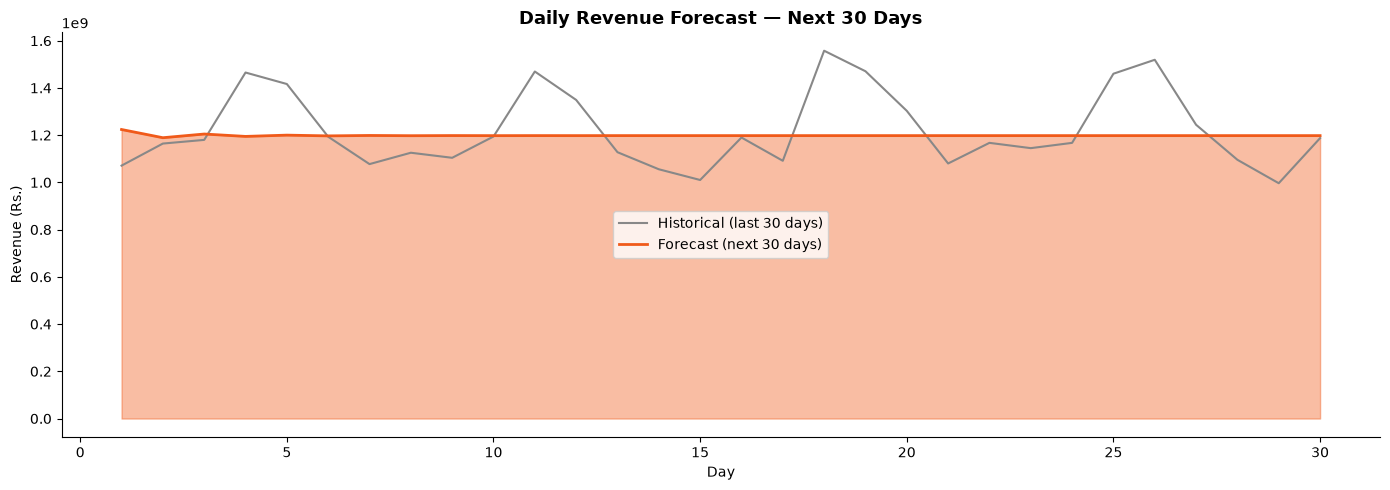

Saved: models/model_arima_forecast.pkl


In [9]:
#daily revenue forecast
print("Training Model 5: Daily Revenue Forecast (ARIMA)...")

# Use order hour of day to simulate daily patterns
daily_orders = orders.groupby("order_dow")["order_id"].count().reset_index()
daily_orders.columns = ["day", "order_count"]
daily_orders["revenue"] = daily_orders["order_count"] * 2500

# Create 90 days of daily data
daily_series = []
for i in range(90):
    dow = i % 7
    base = daily_orders[daily_orders["day"] == dow]["revenue"].values[0]
    noise = np.random.normal(0, base * 0.05)
    daily_series.append(max(0, base + noise))

arima_model = ARIMA(daily_series, order=(2, 1, 2))
arima_result = arima_model.fit()

forecast = arima_result.forecast(steps=30)
forecast_index = range(1, 31)

print(f"AIC: {arima_result.aic:.2f}")
print(f"Average Daily Forecast: Rs. {np.mean(forecast):,.0f}")

# Plot
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(range(1, 31), daily_series[-30:], color="#888888", label="Historical (last 30 days)", linewidth=1.5)
ax.fill_between(forecast_index, forecast, alpha=0.4, color="#f05a1a")
ax.plot(forecast_index, forecast, color="#f05a1a", label="Forecast (next 30 days)", linewidth=2)
ax.set_title("Daily Revenue Forecast — Next 30 Days", fontsize=13, fontweight="bold")
ax.set_xlabel("Day")
ax.set_ylabel("Revenue (Rs.)")
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig("models/chart_daily_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

joblib.dump(arima_result, "models/model_arima_forecast.pkl")
print("Saved: models/model_arima_forecast.pkl")

Training Model 6: Category Sales Prediction...
Top 4 departments: ['produce', 'dairy eggs', 'snacks', 'beverages']
produce: MAE=5888.2, R²=0.6836, Predicted=287 sales
  Saved: models/model_cat_produce.pkl
dairy eggs: MAE=3322.0, R²=0.6729, Predicted=79 sales
  Saved: models/model_cat_dairy_eggs.pkl
snacks: MAE=1848.7, R²=0.6720, Predicted=70 sales
  Saved: models/model_cat_snacks.pkl
beverages: MAE=1827.8, R²=0.6629, Predicted=75 sales
  Saved: models/model_cat_beverages.pkl


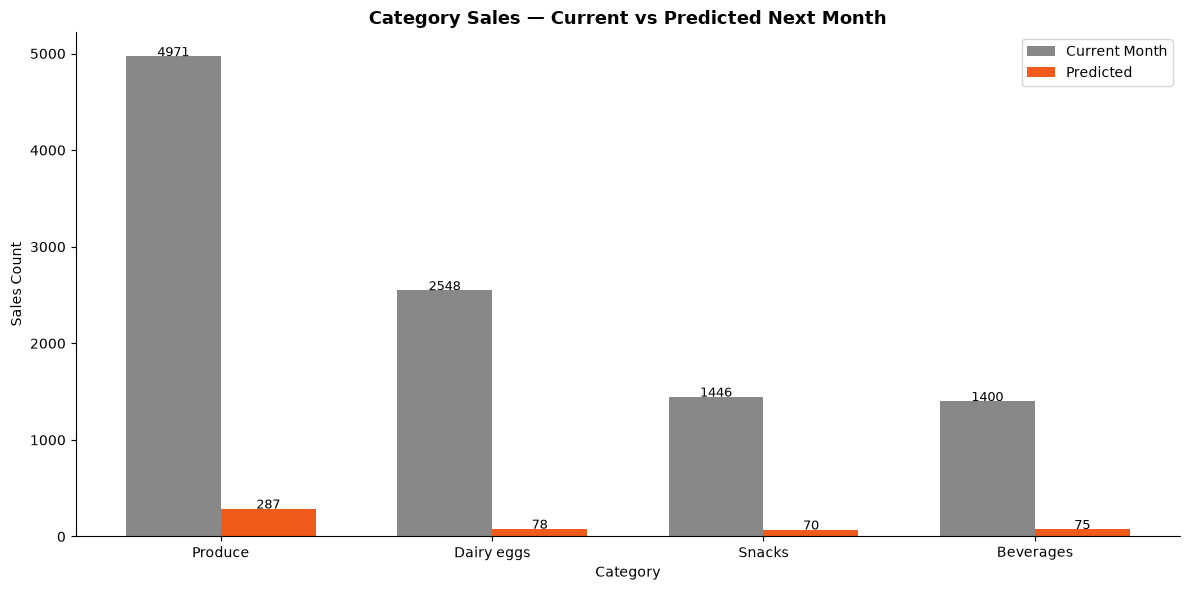

Chart saved!


In [10]:
#category sales prediction
print("Training Model 6: Category Sales Prediction...")

# Get top 4 departments
top_depts = dept_counts.groupby("department")["sales"].sum().nlargest(4).index.tolist()
print(f"Top 4 departments: {top_depts}")

category_models = {}
current_sales = {}
predicted_sales = {}

for dept in top_depts:
    dept_data = dept_counts[dept_counts["department"] == dept].copy()
    dept_data = dept_data.sort_values("order_number")

    X = dept_data[["order_number"]].values
    y = dept_data["sales"].values

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    model = LinearRegression()
    model.fit(X_train, y_train)

    mae = mean_absolute_error(y_test, model.predict(X_test))
    r2 = r2_score(y_test, model.predict(X_test))
    next_pred = model.predict([[25]])[0]

    current_sales[dept] = dept_data["sales"].iloc[-1]
    predicted_sales[dept] = next_pred

    print(f"{dept}: MAE={mae:.1f}, R²={r2:.4f}, Predicted={next_pred:.0f} sales")

    safe_name = dept.replace(" ", "_").replace("/", "_")
    joblib.dump(model, f"models/model_cat_{safe_name}.pkl")
    print(f"  Saved: models/model_cat_{safe_name}.pkl")

# Plot
categories = list(top_depts)
current = [current_sales[c] for c in categories]
predicted = [predicted_sales[c] for c in categories]

x = np.arange(len(categories))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
bars1 = ax.bar(x - width/2, current, width, label="Current Month", color="#888888")
bars2 = ax.bar(x + width/2, predicted, width, label="Predicted", color="#f05a1a")
ax.set_title("Category Sales — Current vs Predicted Next Month", fontsize=13, fontweight="bold")
ax.set_xlabel("Category")
ax.set_ylabel("Sales Count")
ax.set_xticks(x)
ax.set_xticklabels([c.capitalize() for c in categories])
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, str(int(bar.get_height())), ha="center", fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, str(int(bar.get_height())), ha="center", fontsize=9)
plt.tight_layout()
plt.savefig("models/chart_category_sales.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved!")